# Ai2020 기반 DFN 모델 — 1단계 OCP 비교

**목적:** 공통 물리 보정 후 Ai2020 음극, 측정 저율 음극, 측정 GITT 양극 OCP와 각 stoichiometry window의 영향을 같은 데이터로 비교한다.

1. Ai2020 음극·양극 OCP와 공개 window
2. Ai2020 음극·양극 OCP와 재최적화 window
3. Ai2020 음극 + 측정 양극 GITT OCP와 재최적화 window
4. **측정 저율 음극 + 같은 측정 양극 GITT OCP와 재최적화 window**

3과 4는 양극 OCP, geometry, 수송·반응 파라미터, 전류, 평가 구간을 공유한다. 음극 OCP와 그에 따른 window·inventory 차이를 함께 평가한다. `D_s`, `k`, Bruggeman 및 전해질 parameter set의 fitting은 범위 밖이다.

## 0. 실행 환경과 입력 파일

아래 7개 파일을 노트북과 같은 폴더에 둔다. 여섯 번째 파일은 [저장소의 통합 Excel](https://github.com/Rinny-Hi/ai2020_dfn_fitting/blob/main/260902%20Enertech%EC%85%80%20%EB%8D%B0%EC%9D%B4%ED%84%B0%20%EB%AA%A8%EC%9D%8C.xlsx)이며 `ANODE_LOWRATE`(v1/v2 충·방전)와 `PARAMETER_PRIOR` 시트를 사용한다.

- `260610 저율데이터 1.xlsx`
- `260610 저율데이터 2.xlsx`
- `260808 Eneterch셀 열화데이터 v1 6-6.xlsx`
- `260816 Positive GITT 7-7.xlsx`
- `260816 Positive GITT 7-8.xlsx`
- `260902 Enertech셀 데이터 모음.xlsx`
- `Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx` (4절 N3/N4 적분)

측정 음극은 **저율 half-cell OCP**를 사용한다. 신규 음극 GITT OCP는 절대 stoichiometry 기준이 확정되지 않아 이 비교에 포함하지 않는다.

In [1]:
%pip install -q pybamm==26.7.1.0 openpyxl

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
from IPython.display import display
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import differential_evolution, minimize

warnings.filterwarnings("ignore", message="Workbook contains no default style")
REQUIRED_PYBAMM = "26.7.1.0"
if pybamm.__version__ != REQUIRED_PYBAMM:
    raise RuntimeError(
        f"PyBaMM {REQUIRED_PYBAMM}이 필요합니다. 현재 버전: {pybamm.__version__}"
    )

FULL_CELL_LOW_RATE_FILES = [
    "260610 저율데이터 1.xlsx",
    "260610 저율데이터 2.xlsx",
]
DYNAMIC_FILE = "260808 Eneterch셀 열화데이터 v1 6-6.xlsx"
CATHODE_GITT_FILES = [
    "260816 Positive GITT 7-7.xlsx",
    "260816 Positive GITT 7-8.xlsx",
]
MEASURED_ANODE_BOOK = "260902 Enertech셀 데이터 모음.xlsx"
required_files = FULL_CELL_LOW_RATE_FILES + [DYNAMIC_FILE] + CATHODE_GITT_FILES + [MEASURED_ANODE_BOOK]
missing_files = [name for name in required_files if not Path(name).exists()]
if missing_files:
    raise FileNotFoundError("업로드가 필요한 파일: " + ", ".join(missing_files))

print("PyBaMM:", pybamm.__version__)
print("입력 파일 확인:", len(required_files), "개")

PyBaMM: 26.7.1.0
입력 파일 확인: 6 개


In [2]:
# [0-2] C/50 qOCV와 Cell 6-6의 0.5C/1C/2C 원본 데이터 불러오기
TEST_C_RATES = (0.5, 1.0, 2.0)
SOC_GRID = np.linspace(0.0, 1.0, 1001)
DYNAMIC_STEP_INDEX = {
    (0.5, True): 7,
    (0.5, False): 10,
    (1.0, True): 12,
    (1.0, False): 15,
    (2.0, True): 17,
    (2.0, False): 20,
}


def clean_curve(horizontal, vertical):
    horizontal = np.asarray(horizontal, dtype=float).reshape(-1)
    vertical = np.asarray(vertical, dtype=float).reshape(-1)
    valid = np.isfinite(horizontal) & np.isfinite(vertical)
    order = np.argsort(horizontal[valid], kind="stable")
    horizontal = horizontal[valid][order]
    vertical = vertical[valid][order]
    unique_horizontal, inverse = np.unique(horizontal, return_inverse=True)
    if len(unique_horizontal) == len(horizontal):
        return horizontal, vertical
    return unique_horizontal, np.bincount(inverse, weights=vertical) / np.bincount(inverse)


def mean_overlap(curves, number_of_points=3001):
    lower = max(curve[0].min() for curve in curves)
    upper = min(curve[0].max() for curve in curves)
    grid = np.linspace(lower, upper, number_of_points)
    values = np.vstack([np.interp(grid, *curve) for curve in curves])
    return grid, values.mean(axis=0)


def load_full_cell_low_rate(file_names):
    charge_curves, discharge_curves = [], []
    charge_capacities, discharge_capacities = [], []

    for file_name in file_names:
        data = pd.read_excel(file_name, sheet_name="record")
        contiguous_step = data["Step Type"].astype(str).ne(
            data["Step Type"].astype(str).shift()
        ).cumsum()
        branches = {"CC Chg": [], "CC DChg": []}

        for _, branch in data.groupby(contiguous_step):
            step_type = str(branch["Step Type"].iloc[0])
            if step_type not in branches:
                continue
            capacity = pd.to_numeric(branch["Capacity(Ah)"], errors="coerce").to_numpy(float)
            voltage = pd.to_numeric(branch["Voltage(V)"], errors="coerce").to_numpy(float)
            current = float(pd.to_numeric(branch["Current(A)"], errors="coerce").median())
            valid = np.isfinite(capacity) & np.isfinite(voltage)
            capacity, voltage = capacity[valid], voltage[valid]
            if len(capacity) < 50 or capacity.max() < 2.2 or abs(current) > 0.06:
                continue

            end_capacity = float(capacity.max())
            branch_soc = (
                capacity / end_capacity
                if step_type == "CC Chg"
                else 1.0 - capacity / end_capacity
            )
            branch_soc, voltage = clean_curve(branch_soc, voltage)
            branches[step_type].append(
                (end_capacity, np.interp(SOC_GRID, branch_soc, voltage))
            )

        # 첫 방전은 부분 초기충전 직후이므로 제외한다.
        for capacity, voltage in branches["CC Chg"]:
            charge_capacities.append(capacity)
            charge_curves.append(voltage)
        for capacity, voltage in branches["CC DChg"][1:]:
            discharge_capacities.append(capacity)
            discharge_curves.append(voltage)

    mean_charge = np.mean(charge_curves, axis=0)
    mean_discharge = np.mean(discharge_curves, axis=0)
    return {
        "charge": mean_charge,
        "discharge": mean_discharge,
        "qocv": 0.5 * (mean_charge + mean_discharge),
        "capacity_ah": float(
            0.5 * (np.mean(charge_capacities) + np.mean(discharge_capacities))
        ),
        "number_of_charge_curves": len(charge_curves),
        "number_of_discharge_curves": len(discharge_curves),
    }


def load_dynamic_data(file_name):
    step = pd.read_excel(file_name, sheet_name="step")
    record = pd.read_excel(file_name, sheet_name="record")
    record["Date"] = pd.to_datetime(record["Date"])
    experiment = {}

    for key, step_index in DYNAMIC_STEP_INDEX.items():
        branch_row = step[
            (step["Cycle Index"] == 1) & (step["Step Index"] == step_index)
        ].iloc[0]
        previous_row = step[
            (step["Cycle Index"] == 1)
            & (step["Step Number"] == int(branch_row["Step Number"]) - 1)
        ].iloc[0]

        branch = record[
            (record["Date"] >= pd.to_datetime(branch_row["Oneset Date"]))
            & (record["Date"] <= pd.to_datetime(branch_row["End Date"]))
            & (record["Step Type"].astype(str) == str(branch_row["Step Type"]))
        ].copy()
        previous_rest = record[
            (record["Date"] >= pd.to_datetime(previous_row["Oneset Date"]))
            & (record["Date"] <= pd.to_datetime(previous_row["End Date"]))
            & (record["Step Type"].astype(str) == "Rest")
        ].copy()

        time_min = (
            branch["Date"] - branch["Date"].iloc[0]
        ).dt.total_seconds().to_numpy(float) / 60.0
        capacity = pd.to_numeric(branch["Capacity(Ah)"], errors="coerce").to_numpy(float)
        capacity = capacity - capacity[0]
        experiment[key] = {
            "time_min": time_min,
            "voltage_v": pd.to_numeric(branch["Voltage(V)"], errors="coerce").to_numpy(float),
            "capacity_ah": capacity,
            "current_a": abs(float(pd.to_numeric(branch["Current(A)"], errors="coerce").median())),
            "rest_voltage_v": float(pd.to_numeric(previous_rest["Voltage(V)"], errors="coerce").iloc[-1]),
        }
    return experiment


low_rate_data = load_full_cell_low_rate(FULL_CELL_LOW_RATE_FILES)
CELL_CAPACITY_AH = low_rate_data["capacity_ah"]
experimental_curves = load_dynamic_data(DYNAMIC_FILE)

print(f"C/50 charge curves    : {low_rate_data['number_of_charge_curves']}")
print(f"C/50 discharge curves : {low_rate_data['number_of_discharge_curves']}")
print(f"Cell capacity          : {CELL_CAPACITY_AH:.6f} Ah")


C/50 charge curves    : 8
C/50 discharge curves : 8
Cell capacity          : 2.356528 Ah


## 1. 공통 기반 고정

모든 OCP 후보에 동일하게 적용한다.

- Ai2020 electrolyte diffusivity: 원 구현의 단위 해석에 따라 `× 10⁻⁴`
- 음극 평균 입자반경: **3.6920 μm**
- 양극 평균 입자반경: **4.2390 μm**
- 전극 겹침 면적: `45.4 mm × 51.0 mm × 34면`

위 입자반경은 **첨부 노트북의 실행 코드값**이다. 브랜치 간결본의 3.7542/4.2387 μm와 다르므로, 브랜치에 저장된 수치를 이번 실행 결과로 인용하지 않는다.

In [3]:
FARADAY_CONSTANT = 96485.33212
NEGATIVE_RADIUS_M = 3.692e-6
POSITIVE_RADIUS_M = 4.239e-6
OVERLAP_AREA_M2 = 45.4e-3 * 51.0e-3 * 34.0

raw_parameters = pybamm.ParameterValues("Ai2020")
raw_electrolyte_diffusivity = raw_parameters[
    "Electrolyte diffusivity [m2.s-1]"
]


def corrected_electrolyte_diffusivity(concentration, temperature):
    return 1e-4 * raw_electrolyte_diffusivity(concentration, temperature)


common_parameters = raw_parameters.copy()
common_parameters.update(
    {
        "Electrolyte diffusivity [m2.s-1]": corrected_electrolyte_diffusivity,
        "Negative particle radius [m]": NEGATIVE_RADIUS_M,
        "Positive particle radius [m]": POSITIVE_RADIUS_M,
        "Electrode height [m]": 51.0e-3,
        "Electrode width [m]": 45.4e-3,
        "Number of electrodes connected in parallel to make a cell": 34.0,
    }
)

common_changes = pd.DataFrame(
    [
        ["Electrolyte diffusivity", "Ai2020 function", "Ai2020 function × 1e-4", "unit correction"],
        ["Negative particle radius", f"{1e6 * float(raw_parameters['Negative particle radius [m]']):.4f} μm", "3.6920 μm", "SEM/ImageJ mean"],
        ["Positive particle radius", f"{1e6 * float(raw_parameters['Positive particle radius [m]']):.4f} μm", "4.2390 μm", "SEM/ImageJ mean"],
    ],
    columns=["Parameter", "Ai2020", "Stage-1 common value", "Basis"],
)
display(common_changes)

,Parameter,Ai2020,Stage-1 common value,Basis
0,Electrolyte diffusivity,Ai2020 function,Ai2020 function × 1e-4,unit correction
1,Negative particle radius,5.0000 μm,3.6920 μm,SEM/ImageJ mean
2,Positive particle radius,3.0000 μm,4.2390 μm,SEM/ImageJ mean


## 2. OCP와 stoichiometry window

양극은 두 GITT 반복시험의 장시간 완화전압을 평균해 사용한다. 측정 음극은 통합 Excel의 저율 half-cell v1/v2 충·방전을 같은 용량 기준으로 변환·평균한다. 이때 절대 x축은 Ai2020 `c_s,max`, 활물질 분율·두께 및 10 mm disk 면적에 의존하므로 **독립적인 실측 절대 stoichiometry 기준이 아니다**.

각 OCP 조합의 window는 같은 C/50 충·방전 평균 qOCV의 2–98% SOC RMSE를 최소화한다. SOC 0/100% 끝점 오차는 각각 10 mV 이내로 제한한다. 측정 OCP의 보간 범위와 선택 window의 관계를 함께 표시한다.

4.2 V는 full-cell 단자전압이므로 양극 OCP 자체를 `4.2 V vs Li/Li+`에서 절단하지 않는다.

In [4]:
PUBLISHED_WINDOW = {"x0": 0.0065, "x100": 0.8400, "y0": 0.9651, "y100": 0.4350}


def evaluate_parameter_function(parameter_values, name, grid):
    function = parameter_values[name]
    return np.array(
        [
            float(
                np.asarray(
                    function(pybamm.Scalar(float(value))).evaluate(), dtype=float
                ).reshape(-1)[0]
            )
            for value in grid
        ]
    )


ocp_grid = np.linspace(0.001, 0.999, 3001)
AI2020_OCP = {
    "negative": (
        ocp_grid,
        evaluate_parameter_function(common_parameters, "Negative electrode OCP [V]", ocp_grid),
    ),
    "positive": (
        ocp_grid,
        evaluate_parameter_function(common_parameters, "Positive electrode OCP [V]", ocp_grid),
    ),
}


In [5]:
def duration_to_seconds(value):
    if pd.isna(value):
        return np.nan
    if hasattr(value, "total_seconds"):
        return float(value.total_seconds())
    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value) * 86400.0
    parts = str(value).strip().split(":")
    if len(parts) != 3:
        return np.nan
    hours, minutes, seconds = map(float, parts)
    return 3600.0 * hours + 60.0 * minutes + seconds


def duration_seconds(values):
    return values.map(duration_to_seconds)



def build_cathode_gitt_ocp(file_names, parameters):
    disk_area_m2 = np.pi * (0.01 / 2.0) ** 2
    disk_capacity_ah = (
        FARADAY_CONSTANT
        * float(parameters["Maximum concentration in positive electrode [mol.m-3]"])
        * float(parameters["Positive electrode active material volume fraction"])
        * float(parameters["Positive electrode thickness [m]"])
        * disk_area_m2
        / 3600.0
    )
    lithiation_curves, delithiation_curves = [], []

    for file_name in file_names:
        step = pd.read_excel(file_name, sheet_name="step")
        record = pd.read_excel(file_name, sheet_name="record")
        step["duration_s"] = duration_seconds(step["Step Time"])
        cycle = step[step["Cycle Index"] == 2].reset_index(drop=True)
        record["Date"] = pd.to_datetime(record["Date"])
        record = record.sort_values("Date").reset_index(drop=True)
        record_time_ns = record["Date"].to_numpy(dtype="datetime64[ns]").astype(np.int64)
        cumulative = {"CC Chg": 0.0, "CC DChg": 0.0}
        points = {"CC Chg": [], "CC DChg": []}

        for row_index, row in cycle.iterrows():
            step_type = str(row["Step Type"])
            if step_type not in cumulative or not (0 < row["duration_s"] <= 700):
                continue
            rest_index = row_index + 1
            following_rests = []
            while rest_index < len(cycle) and str(cycle.iloc[rest_index]["Step Type"]) == "Rest":
                if cycle.iloc[rest_index]["duration_s"] >= 3500:
                    following_rests.append(cycle.iloc[rest_index])
                rest_index += 1
            if not following_rests:
                continue
            relaxed_state = following_rests[-1]

            onset_ns = pd.Timestamp(row["Oneset Date"]).value
            end_ns = pd.Timestamp(row["End Date"]).value
            left = int(np.searchsorted(record_time_ns, onset_ns, side="left"))
            right = int(np.searchsorted(record_time_ns, end_ns, side="right"))
            pulse_record = record.iloc[left:right]
            pulse_record = pulse_record[pulse_record["Step Type"].astype(str) == step_type]
            pulse_capacity = pd.to_numeric(
                pulse_record["Capacity(Ah)"], errors="coerce"
            ).max()
            cumulative[step_type] += float(pulse_capacity)
            points[step_type].append(
                (cumulative[step_type], float(relaxed_state["End Voltage(V)"]))
            )

        charge = np.asarray(points["CC Chg"], dtype=float)
        discharge = np.asarray(points["CC DChg"], dtype=float)
        delithiation_curves.append(
            clean_curve(1.0 - charge[:, 0] / disk_capacity_ah, charge[:, 1])
        )
        discharge_span = discharge[:, 0].max() / disk_capacity_ah
        lithiation_curves.append(
            clean_curve((1.0 - discharge_span) + discharge[:, 0] / disk_capacity_ah, discharge[:, 1])
        )

    mean_lithiation = mean_overlap(lithiation_curves)
    mean_delithiation = mean_overlap(delithiation_curves)
    return mean_overlap([mean_lithiation, mean_delithiation])




CATHODE_GITT_OCP = build_cathode_gitt_ocp(
    CATHODE_GITT_FILES, raw_parameters
)


def build_measured_anode_lowrate_ocp(book_name, parameters):
    frame = pd.read_excel(book_name, sheet_name="ANODE_LOWRATE", header=8)
    prior = pd.read_excel(book_name, sheet_name="PARAMETER_PRIOR", header=7)
    diameter_row = prior.loc[prior["parameter"].astype(str).eq("disk_diameter_m"), "value"]
    if diameter_row.empty:
        raise ValueError("PARAMETER_PRIOR에 disk_diameter_m이 없습니다")
    disk_diameter_m = float(diameter_row.iloc[0])
    disk_area_m2 = np.pi * (disk_diameter_m / 2.0) ** 2
    disk_capacity_ah = (
        FARADAY_CONSTANT
        * float(parameters["Maximum concentration in negative electrode [mol.m-3]"])
        * float(parameters["Negative electrode active material volume fraction"])
        * float(parameters["Negative electrode thickness [m]"])
        * disk_area_m2 / 3600.0
    )
    if disk_capacity_ah <= 0:
        raise ValueError("음극 disk 기준 용량이 양수가 아닙니다")

    lithiation_curves, delithiation_curves = [], []
    for version in ("v1", "v2"):
        branches = {}
        for direction in ("charge", "discharge"):
            selected = frame.loc[
                frame["source_version"].astype(str).eq(version)
                & frame["direction"].astype(str).eq(direction)
            ]
            capacity = pd.to_numeric(selected["Q_Ah"], errors="coerce").to_numpy(float)
            voltage = pd.to_numeric(selected["V_V"], errors="coerce").to_numpy(float)
            finite = np.isfinite(capacity) & np.isfinite(voltage)
            capacity, voltage = capacity[finite], voltage[finite]
            if capacity.size < 2:
                raise ValueError(f"ANODE_LOWRATE {version}/{direction} 데이터가 부족합니다")
            branches[direction] = (capacity, voltage)
        q_discharge, v_discharge = branches["discharge"]
        q_charge, v_charge = branches["charge"]
        lithiation_curves.append(clean_curve(q_discharge / disk_capacity_ah, v_discharge))
        delithiation_curves.append(
            clean_curve(q_charge.max() / disk_capacity_ah - q_charge / disk_capacity_ah, v_charge)
        )

    mean_lithiation = mean_overlap(lithiation_curves)
    mean_delithiation = mean_overlap(delithiation_curves)
    return mean_overlap([mean_lithiation, mean_delithiation]), disk_capacity_ah


MEASURED_ANODE_OCP, ANODE_DISK_CAPACITY_AH = build_measured_anode_lowrate_ocp(
    MEASURED_ANODE_BOOK, raw_parameters
)
print(
    f"Measured anode x support: {MEASURED_ANODE_OCP[0].min():.6f}–"
    f"{MEASURED_ANODE_OCP[0].max():.6f}; assumed disk Q={ANODE_DISK_CAPACITY_AH:.6f} Ah"
)

Measured anode x support: 0.000000–0.869829; assumed disk Q=0.002819 Ah


In [6]:
# [3-2] 각 OCP 조합에서 stoichiometry window를 독립적으로 선정한다.
def predict_full_cell_ocv(window_vector, anode_curve, cathode_curve, soc=SOC_GRID):
    x0, x100, y100, y0 = map(float, window_vector)
    negative_stoichiometry = x0 + soc * (x100 - x0)
    positive_stoichiometry = y0 - soc * (y0 - y100)
    negative_ocp = np.interp(negative_stoichiometry, *anode_curve)
    positive_ocp = np.interp(positive_stoichiometry, *cathode_curve)
    return positive_ocp - negative_ocp


def fit_stoichiometry_window(anode_curve, cathode_curve, random_seed):
    anode_min, anode_max = float(anode_curve[0].min()), float(anode_curve[0].max())
    cathode_min, cathode_max = float(cathode_curve[0].min()), float(cathode_curve[0].max())
    minimum_width = CELL_CAPACITY_AH / 6.0
    maximum_width = CELL_CAPACITY_AH / 2.4
    fitting_region = (SOC_GRID >= 0.02) & (SOC_GRID <= 0.98)

    def voltage_mse(window_vector):
        error = (
            predict_full_cell_ocv(window_vector, anode_curve, cathode_curve)
            - low_rate_data["qocv"]
        )
        return float(np.mean(error[fitting_region] ** 2))

    def constraint_violation(window_vector):
        x0, x100, y100, y0 = window_vector
        delta_x, delta_y = x100 - x0, y0 - y100
        endpoint_error = (
            predict_full_cell_ocv(
                window_vector, anode_curve, cathode_curve, SOC_GRID[[0, -1]]
            )
            - low_rate_data["qocv"][[0, -1]]
        )
        violations = [
            max(0.0, minimum_width - delta_x),
            max(0.0, delta_x - maximum_width),
            max(0.0, minimum_width - delta_y),
            max(0.0, delta_y - maximum_width),
            max(0.0, abs(endpoint_error[0]) - 0.010),
            max(0.0, abs(endpoint_error[1]) - 0.010),
        ]
        return float(np.sum(np.square(violations)))

    def penalized_objective(window_vector):
        return voltage_mse(window_vector) + 1e4 * constraint_violation(window_vector)

    bounds = [
        (anode_min, anode_max),
        (anode_min, anode_max),
        (cathode_min, cathode_max),
        (cathode_min, cathode_max),
    ]
    global_result = differential_evolution(
        penalized_objective,
        bounds=bounds,
        seed=random_seed,
        popsize=16,
        maxiter=350,
        tol=1e-10,
        polish=False,
        workers=1,
    )
    constraints = [
        {"type": "ineq", "fun": lambda z: (z[1] - z[0]) - minimum_width},
        {"type": "ineq", "fun": lambda z: maximum_width - (z[1] - z[0])},
        {"type": "ineq", "fun": lambda z: (z[3] - z[2]) - minimum_width},
        {"type": "ineq", "fun": lambda z: maximum_width - (z[3] - z[2])},
        {
            "type": "ineq",
            "fun": lambda z: 0.010
            - abs(
                predict_full_cell_ocv(z, anode_curve, cathode_curve, SOC_GRID[[0]])[0]
                - low_rate_data["qocv"][0]
            ),
        },
        {
            "type": "ineq",
            "fun": lambda z: 0.010
            - abs(
                predict_full_cell_ocv(z, anode_curve, cathode_curve, SOC_GRID[[-1]])[0]
                - low_rate_data["qocv"][-1]
            ),
        },
    ]
    local_result = minimize(
        voltage_mse,
        x0=global_result.x,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 3000, "ftol": 1e-14, "disp": False},
    )
    if constraint_violation(local_result.x) <= constraint_violation(global_result.x) + 1e-12:
        return np.asarray(local_result.x, dtype=float)
    return np.asarray(global_result.x, dtype=float)




def vector_to_window(vector):
    x0, x100, y100, y0 = map(float, vector)
    return {"x0": x0, "x100": x100, "y0": y0, "y100": y100}


published_vector = np.array([
    PUBLISHED_WINDOW["x0"], PUBLISHED_WINDOW["x100"],
    PUBLISHED_WINDOW["y100"], PUBLISHED_WINDOW["y0"],
])
ai_refit_vector = fit_stoichiometry_window(
    AI2020_OCP["negative"], AI2020_OCP["positive"], random_seed=260924
)
improved_vector = fit_stoichiometry_window(
    AI2020_OCP["negative"], CATHODE_GITT_OCP, random_seed=260921
)
measured_anode_vector = fit_stoichiometry_window(
    MEASURED_ANODE_OCP, CATHODE_GITT_OCP, random_seed=261020
)
AI_REFIT_WINDOW = vector_to_window(ai_refit_vector)
IMPROVED_WINDOW = vector_to_window(improved_vector)
MEASURED_ANODE_WINDOW = vector_to_window(measured_anode_vector)

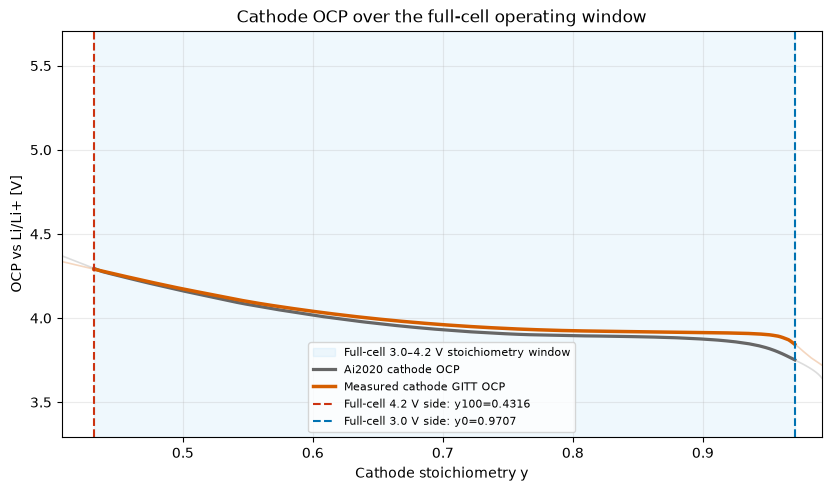

,Case,x0,x100,y0,y100,Qn [Ah],Qp [Ah],qOCV RMSE 2–98% [mV],SOC0 error [mV],SOC100 error [mV],Anode support x_min,Anode support x_max
0,Ai2020 published,0.006500,0.840000,0.965100,0.435000,2.827268,4.445440,39.551839,53.05054,-13.492061,NaN,NaN
1,Ai2020 OCP + refit window,0.003180,0.985066,0.867768,0.441824,2.400000,5.532472,16.354171,10.00000,1.789849,NaN,NaN
2,Measured cathode OCP + refit window,0.003803,0.954167,0.970716,0.431646,2.479606,4.371468,6.242655,10.00000,-0.898535,NaN,NaN
3,Measured anode + cathode OCP + refit window,0.002150,0.739784,0.976291,0.448293,3.194710,4.463131,8.219708,10.00000,-8.909631,0.0,0.869829


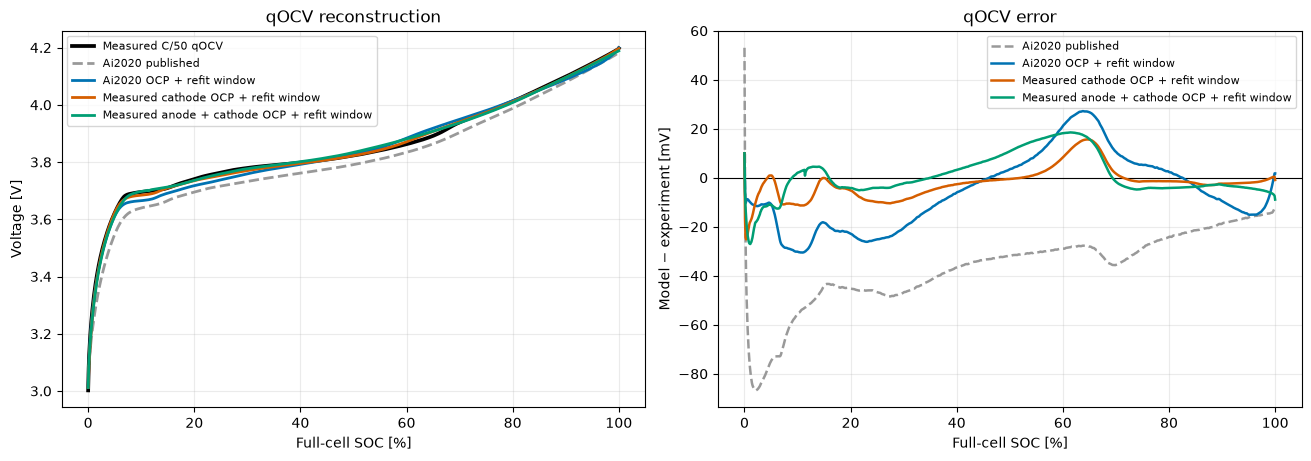

In [7]:
# 양극 OCP는 full-cell 3.0–4.2 V에 대응하는 최종 stoichiometry
# window에서 비교한다. 4.2 V는 full-cell 단자전압이므로 양극 OCP를
# 4.2 V vs Li/Li+에서 수평 절단하지 않는다.
y_charge_side = IMPROVED_WINDOW["y100"]
y_discharge_side = IMPROVED_WINDOW["y0"]
comparison_y = np.linspace(y_charge_side, y_discharge_side, 1000)
ai2020_positive_in_window = np.interp(
    comparison_y, *AI2020_OCP["positive"]
)
measured_positive_in_window = np.interp(
    comparison_y, *CATHODE_GITT_OCP
)

figure, axis = plt.subplots(figsize=(8.2, 4.8), constrained_layout=True)
# 범위 밖 곡선은 출처와 측정 범위 확인용으로만 흐리게 표시한다.
axis.plot(
    *AI2020_OCP["positive"], color="#777777", lw=1.2, alpha=0.25
)
axis.plot(
    *CATHODE_GITT_OCP, color="#D55E00", lw=1.2, alpha=0.25
)
axis.axvspan(
    y_charge_side,
    y_discharge_side,
    color="#56B4E9",
    alpha=0.09,
    label="Full-cell 3.0–4.2 V stoichiometry window",
)
axis.plot(
    comparison_y,
    ai2020_positive_in_window,
    color="#666666",
    lw=2.3,
    label="Ai2020 cathode OCP",
)
axis.plot(
    comparison_y,
    measured_positive_in_window,
    color="#D55E00",
    lw=2.5,
    label="Measured cathode GITT OCP",
)
axis.axvline(
    y_charge_side,
    color="#CC3311",
    ls="--",
    lw=1.5,
    label=f"Full-cell 4.2 V side: y100={y_charge_side:.4f}",
)
axis.axvline(
    y_discharge_side,
    color="#0072B2",
    ls="--",
    lw=1.5,
    label=f"Full-cell 3.0 V side: y0={y_discharge_side:.4f}",
)
margin = 0.03
axis.set_xlim(
    max(float(CATHODE_GITT_OCP[0].min()), y_charge_side - margin),
    min(float(CATHODE_GITT_OCP[0].max()), y_discharge_side + margin),
)
axis.set(
    xlabel="Cathode stoichiometry y",
    ylabel="OCP vs Li/Li+ [V]",
    title="Cathode OCP over the full-cell operating window",
)
axis.grid(alpha=0.25)
axis.legend(fontsize=8)
plt.show()

# qOCV: 공개 window → window만 재최적화 → 실험 양극 OCP+window 재최적화
qocv_cases = [
    ("Ai2020 published", published_vector, AI2020_OCP["negative"], AI2020_OCP["positive"], "#999999", "--"),
    ("Ai2020 OCP + refit window", ai_refit_vector, AI2020_OCP["negative"], AI2020_OCP["positive"], "#0072B2", "-"),
    ("Measured cathode OCP + refit window", improved_vector, AI2020_OCP["negative"], CATHODE_GITT_OCP, "#D55E00", "-"),
    ("Measured anode + cathode OCP + refit window", measured_anode_vector, MEASURED_ANODE_OCP, CATHODE_GITT_OCP, "#009E73", "-"),
]
fitting_region = (SOC_GRID >= 0.02) & (SOC_GRID <= 0.98)
qocv_rows, qocv_predictions = [], {}

for name, vector, anode_ocp, cathode_ocp, color, style in qocv_cases:
    prediction = predict_full_cell_ocv(vector, anode_ocp, cathode_ocp)
    qocv_predictions[name] = prediction
    error_mv = 1000.0 * (prediction - low_rate_data["qocv"])
    x0, x100, y100, y0 = vector
    qocv_rows.append(
        {
            "Case": name,
            "x0": x0, "x100": x100, "y0": y0, "y100": y100,
            "Qn [Ah]": CELL_CAPACITY_AH / (x100 - x0),
            "Qp [Ah]": CELL_CAPACITY_AH / (y0 - y100),
            "qOCV RMSE 2–98% [mV]": np.sqrt(np.mean(error_mv[fitting_region] ** 2)),
            "SOC0 error [mV]": error_mv[0],
            "SOC100 error [mV]": error_mv[-1],
        }
    )

window_results = pd.DataFrame(qocv_rows)
window_results["Anode support x_min"] = [np.nan, np.nan, np.nan, MEASURED_ANODE_OCP[0].min()]
window_results["Anode support x_max"] = [np.nan, np.nan, np.nan, MEASURED_ANODE_OCP[0].max()]
display(window_results.round(6))

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].plot(SOC_GRID * 100, low_rate_data["qocv"], color="black", lw=2.7, label="Measured C/50 qOCV")
axes[1].axhline(0.0, color="black", lw=0.8)
for name, _, _, _, color, style in qocv_cases:
    prediction = qocv_predictions[name]
    axes[0].plot(SOC_GRID * 100, prediction, color=color, ls=style, lw=2.0, label=name)
    axes[1].plot(SOC_GRID * 100, 1000 * (prediction - low_rate_data["qocv"]), color=color, ls=style, lw=1.8, label=name)
axes[0].set(title="qOCV reconstruction", xlabel="Full-cell SOC [%]", ylabel="Voltage [V]")
axes[1].set(title="qOCV error", xlabel="Full-cell SOC [%]", ylabel="Model − experiment [mV]")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.show()

## 3. Capacity-consistent inventory와 DFN 검증

각 재최적화 window에서 `Q_n`, `Q_p`를 계산하고, 동일한 면적·두께·활물질 분율을 쓰도록 `c_s,max,n/p`를 역산한다. 공통 OCP 쌍에 대해 **Ai2020 음극 → 측정 음극** 변화가 qOCV와 0.5C/1C/2C 충·방전 전압·cut-off 용량에 미치는 영향을 비교한다. `c_s,max`는 window에 따른 bookkeeping 값이며 독립 측정값이 아니다.

In [8]:
def build_candidate_parameters(base_parameters, window, positive_ocp, negative_ocp=None):
    parameters = base_parameters.copy()
    qn_ah = CELL_CAPACITY_AH / (window["x100"] - window["x0"])
    qp_ah = CELL_CAPACITY_AH / (window["y0"] - window["y100"])
    csmax_n = 3600.0 * qn_ah / (
        FARADAY_CONSTANT * OVERLAP_AREA_M2
        * float(parameters["Negative electrode thickness [m]"])
        * float(parameters["Negative electrode active material volume fraction"])
    )
    csmax_p = 3600.0 * qp_ah / (
        FARADAY_CONSTANT * OVERLAP_AREA_M2
        * float(parameters["Positive electrode thickness [m]"])
        * float(parameters["Positive electrode active material volume fraction"])
    )
    positive_grid, positive_voltage = positive_ocp

    def measured_positive_ocp(stoichiometry):
        return pybamm.Interpolant(
            positive_grid, positive_voltage, stoichiometry,
            name="Measured cathode GITT OCP", interpolator="linear"
        )

    updates = {
        "Maximum concentration in negative electrode [mol.m-3]": csmax_n,
        "Maximum concentration in positive electrode [mol.m-3]": csmax_p,
        "Positive electrode OCP [V]": measured_positive_ocp,
    }
    if negative_ocp is not None:
        negative_grid, negative_voltage = negative_ocp

        def measured_negative_ocp(stoichiometry):
            return pybamm.Interpolant(
                negative_grid, negative_voltage, stoichiometry,
                name="Measured anode low-rate OCP", interpolator="linear"
            )

        updates["Negative electrode OCP [V]"] = measured_negative_ocp
    parameters.update(updates)
    return parameters, csmax_n, csmax_p


improved_parameters, improved_csmax_n, improved_csmax_p = build_candidate_parameters(
    common_parameters, IMPROVED_WINDOW, CATHODE_GITT_OCP
)
measured_anode_parameters, measured_anode_csmax_n, measured_anode_csmax_p = build_candidate_parameters(
    common_parameters, MEASURED_ANODE_WINDOW, CATHODE_GITT_OCP, MEASURED_ANODE_OCP
)
baseline_csmax_n = float(common_parameters["Maximum concentration in negative electrode [mol.m-3]"])
baseline_csmax_p = float(common_parameters["Maximum concentration in positive electrode [mol.m-3]"])

parameter_summary = pd.DataFrame(
    [
        ["Negative OCP", "Ai2020", "Ai2020", "Measured low-rate v1/v2"],
        ["Positive OCP", "Ai2020", "Measured GITT mean", "Measured GITT mean"],
        ["x0 / x100", f"{PUBLISHED_WINDOW['x0']:.6f} / {PUBLISHED_WINDOW['x100']:.6f}", f"{IMPROVED_WINDOW['x0']:.6f} / {IMPROVED_WINDOW['x100']:.6f}", f"{MEASURED_ANODE_WINDOW['x0']:.6f} / {MEASURED_ANODE_WINDOW['x100']:.6f}"],
        ["y0 / y100", f"{PUBLISHED_WINDOW['y0']:.6f} / {PUBLISHED_WINDOW['y100']:.6f}", f"{IMPROVED_WINDOW['y0']:.6f} / {IMPROVED_WINDOW['y100']:.6f}" , f"{MEASURED_ANODE_WINDOW['y0']:.6f} / {MEASURED_ANODE_WINDOW['y100']:.6f}"],
        ["c_s,max,n [mol m-3]", f"{baseline_csmax_n:.1f}", f"{improved_csmax_n:.1f}", f"{measured_anode_csmax_n:.1f}"],
        ["c_s,max,p [mol m-3]", f"{baseline_csmax_p:.1f}", f"{improved_csmax_p:.1f}", f"{measured_anode_csmax_p:.1f}"],
    ],
    columns=["Item", "Baseline", "Measured cathode", "Measured anode + cathode"],
)
display(parameter_summary)

,Item,Baseline,Measured cathode,Measured anode + cathode
0,Negative OCP,Ai2020,Ai2020,Measured low-rate v1/v2
1,Positive OCP,Ai2020,Measured GITT mean,Measured GITT mean
2,x0 / x100,0.006500 / 0.840000,0.003803 / 0.954167,0.002150 / 0.739784
3,y0 / y100,0.965100 / 0.435000,0.970716 / 0.431646,0.976291 / 0.448293
4,"c_s,max,n [mol m-3]",28700.0,25184.2,32447.1
5,"c_s,max,p [mol m-3]",49943.0,49143.1,50173.6


In [9]:
# [결과-1] DFN 실행 및 실험 대비 오차 계산
def stage_ocv(stage):
    window = stage["window"]
    return predict_full_cell_ocv(
        [window["x0"], window["x100"], window["y100"], window["y0"]],
        stage["anode_ocp"],
        stage["cathode_ocp"],
    )


def initial_soc_from_rest_voltage(stage, rest_voltage_v):
    qocv = stage_ocv(stage)
    order = np.argsort(qocv, kind="stable")
    unique_voltage, unique_index = np.unique(qocv[order], return_index=True)
    return float(np.interp(rest_voltage_v, unique_voltage, SOC_GRID[order][unique_index]))


def run_dfn_branch(stage, c_rate, is_charge):
    experiment = experimental_curves[(c_rate, is_charge)]
    initial_soc = initial_soc_from_rest_voltage(stage, experiment["rest_voltage_v"])
    window = stage["window"]
    initial_x = window["x0"] + initial_soc * (window["x100"] - window["x0"])
    initial_y = window["y0"] - initial_soc * (window["y0"] - window["y100"])
    branch_parameters = stage["parameters"].copy()
    branch_parameters.update(
        {
            "Initial concentration in negative electrode [mol.m-3]": initial_x * stage["c_s_max_n"],
            "Initial concentration in positive electrode [mol.m-3]": initial_y * stage["c_s_max_p"],
        }
    )

    direction = "Charge" if is_charge else "Discharge"
    cutoff_voltage = 4.2 if is_charge else 3.0
    protocol = f"{direction} at {experiment['current_a']} A until {cutoff_voltage} V"
    simulation = pybamm.Simulation(
        pybamm.lithium_ion.DFN({"thermal": "isothermal"}),
        parameter_values=branch_parameters,
        experiment=pybamm.Experiment([protocol], period="10 seconds"),
        var_pts={"x_n": 15, "x_s": 15, "x_p": 15, "r_n": 15, "r_p": 15},
        solver=pybamm.IDAKLUSolver(rtol=1e-6, atol=1e-8),
    )
    solution = simulation.solve()
    time_s = np.asarray(solution["Time [s]"].entries, dtype=float)
    voltage_v = np.asarray(solution["Terminal voltage [V]"].entries, dtype=float)
    current_a = np.asarray(solution["Current [A]"].entries, dtype=float)
    anode_potential_v = np.asarray(
        solution["Negative electrode surface potential difference at separator interface [V]"].entries,
        dtype=float,
    ).squeeze()
    capacity_ah = cumulative_trapezoid(np.abs(current_a), time_s, initial=0.0) / 3600.0
    if is_charge:
        full_cell_soc_pct = 100.0 * (initial_soc + capacity_ah / CELL_CAPACITY_AH)
    else:
        full_cell_soc_pct = 100.0 * (initial_soc - capacity_ah / CELL_CAPACITY_AH)
    return {
        "time_min": time_s / 60.0,
        "voltage_v": voltage_v,
        "anode_potential_v": anode_potential_v,
        "capacity_ah": capacity_ah,
        "full_cell_soc_pct": np.clip(full_cell_soc_pct, 0.0, 100.0),
        "initial_soc_pct": 100.0 * initial_soc,
    }


def compare_with_experiment(experiment, simulation):
    experiment_time = experiment["time_min"] - experiment["time_min"][0]
    simulation_time = simulation["time_min"] - simulation["time_min"][0]
    common_end = 0.995 * min(experiment_time[-1], simulation_time[-1])
    full_grid = np.linspace(0.0, common_end, 400)
    center_start = 0.10 * CELL_CAPACITY_AH / experiment["current_a"] * 60.0
    center_end = min(0.70 * CELL_CAPACITY_AH / experiment["current_a"] * 60.0, common_end)
    if center_end <= center_start:
        center_grid = full_grid[full_grid >= 0.10 * common_end]
    else:
        center_grid = np.linspace(center_start, center_end, 160)

    def error_mv(time_grid):
        return 1000.0 * (
            np.interp(time_grid, simulation_time, simulation["voltage_v"])
            - np.interp(time_grid, experiment_time, experiment["voltage_v"])
        )

    full_error = error_mv(full_grid)
    center_error = error_mv(center_grid)
    experiment_capacity = experiment["capacity_ah"][-1]
    simulation_capacity = simulation["capacity_ah"][-1]
    return {
        "full_RMSE_mV": float(np.sqrt(np.mean(full_error**2))),
        "full_MAE_mV": float(np.mean(np.abs(full_error))),
        "center_10_70_RMSE_mV": float(np.sqrt(np.mean(center_error**2))),
        "center_10_70_MAE_mV": float(np.mean(np.abs(center_error))),
        "capacity_error_pct": float(100.0 * (simulation_capacity - experiment_capacity) / experiment_capacity),
    }


In [10]:
stages = {
    "Baseline: Ai2020 OCP/window": {
        "parameters": common_parameters,
        "window": PUBLISHED_WINDOW,
        "c_s_max_n": baseline_csmax_n,
        "c_s_max_p": baseline_csmax_p,
        "anode_ocp": AI2020_OCP["negative"],
        "cathode_ocp": AI2020_OCP["positive"],
    },
    "Improved: measured cathode OCP/refit window": {
        "parameters": improved_parameters,
        "window": IMPROVED_WINDOW,
        "c_s_max_n": improved_csmax_n,
        "c_s_max_p": improved_csmax_p,
        "anode_ocp": AI2020_OCP["negative"],
        "cathode_ocp": CATHODE_GITT_OCP,
    },
    "Measured: anode + cathode OCP/refit window": {
        "parameters": measured_anode_parameters,
        "window": MEASURED_ANODE_WINDOW,
        "c_s_max_n": measured_anode_csmax_n,
        "c_s_max_p": measured_anode_csmax_p,
        "anode_ocp": MEASURED_ANODE_OCP,
        "cathode_ocp": CATHODE_GITT_OCP,
    },
}

simulations, metric_rows = {}, []
for stage_name, stage in stages.items():
    for c_rate in TEST_C_RATES:
        for is_charge in (True, False):
            direction = "Charge" if is_charge else "Discharge"
            print(f"{stage_name} | {c_rate:g}C {direction}")
            simulation = run_dfn_branch(stage, c_rate, is_charge)
            simulations[(stage_name, c_rate, is_charge)] = simulation
            metric_rows.append(
                {
                    "Model": stage_name,
                    "C-rate": c_rate,
                    "Direction": direction,
                    **compare_with_experiment(
                        experimental_curves[(c_rate, is_charge)], simulation
                    ),
                }
            )

metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

Baseline: Ai2020 OCP/window | 0.5C Charge


Baseline: Ai2020 OCP/window | 0.5C Discharge


Baseline: Ai2020 OCP/window | 1C Charge


Baseline: Ai2020 OCP/window | 1C Discharge


Baseline: Ai2020 OCP/window | 2C Charge


...

Measured: anode + cathode OCP/refit window | 1C Charge


Measured: anode + cathode OCP/refit window | 1C Discharge


Measured: anode + cathode OCP/refit window | 2C Charge


Measured: anode + cathode OCP/refit window | 2C Discharge


,Model,C-rate,Direction,full_RMSE_mV,full_MAE_mV,center_10_70_RMSE_mV,center_10_70_MAE_mV,capacity_error_pct
0,Baseline: Ai2020 OCP/window,0.5,Charge,79.443,72.800,91.831,90.150,0.964
1,Baseline: Ai2020 OCP/window,0.5,Discharge,30.100,21.199,10.312,9.188,1.389
2,Baseline: Ai2020 OCP/window,1.0,Charge,78.905,74.013,86.789,85.191,1.470
3,Baseline: Ai2020 OCP/window,1.0,Discharge,29.856,25.665,18.769,16.229,1.046
4,Baseline: Ai2020 OCP/window,2.0,Charge,75.054,71.408,76.051,73.779,2.727
5,Baseline: Ai2020 OCP/window,2.0,Discharge,35.448,23.925,19.087,15.048,-3.781
6,Improved: measured cathode OCP/refit window,0.5,Charge,47.292,40.221,53.661,50.890,-2.396
7,Improved: measured cathode OCP/refit window,0.5,Discharge,47.228,39.021,28.745,24.737,0.178
8,Improved: measured cathode OCP/refit window,1.0,Charge,50.726,43.173,48.232,45.891,-3.280
9,Improved: measured cathode OCP/refit window,1.0,Discharge,49.135,41.824,34.816,29.216,-0.072


,Model,Voltage_full_RMSE_mV,Voltage_10_70_RMSE_mV,Cutoff_capacity_RMSE_pct,Max_abs_cutoff_capacity_error_pct
0,Baseline: Ai2020 OCP/window,59.476,61.335,2.154,3.781
1,Improved: measured cathode OCP/refit window,46.689,39.363,3.152,4.797
2,Measured: anode + cathode OCP/refit window,51.618,46.311,1.873,4.283


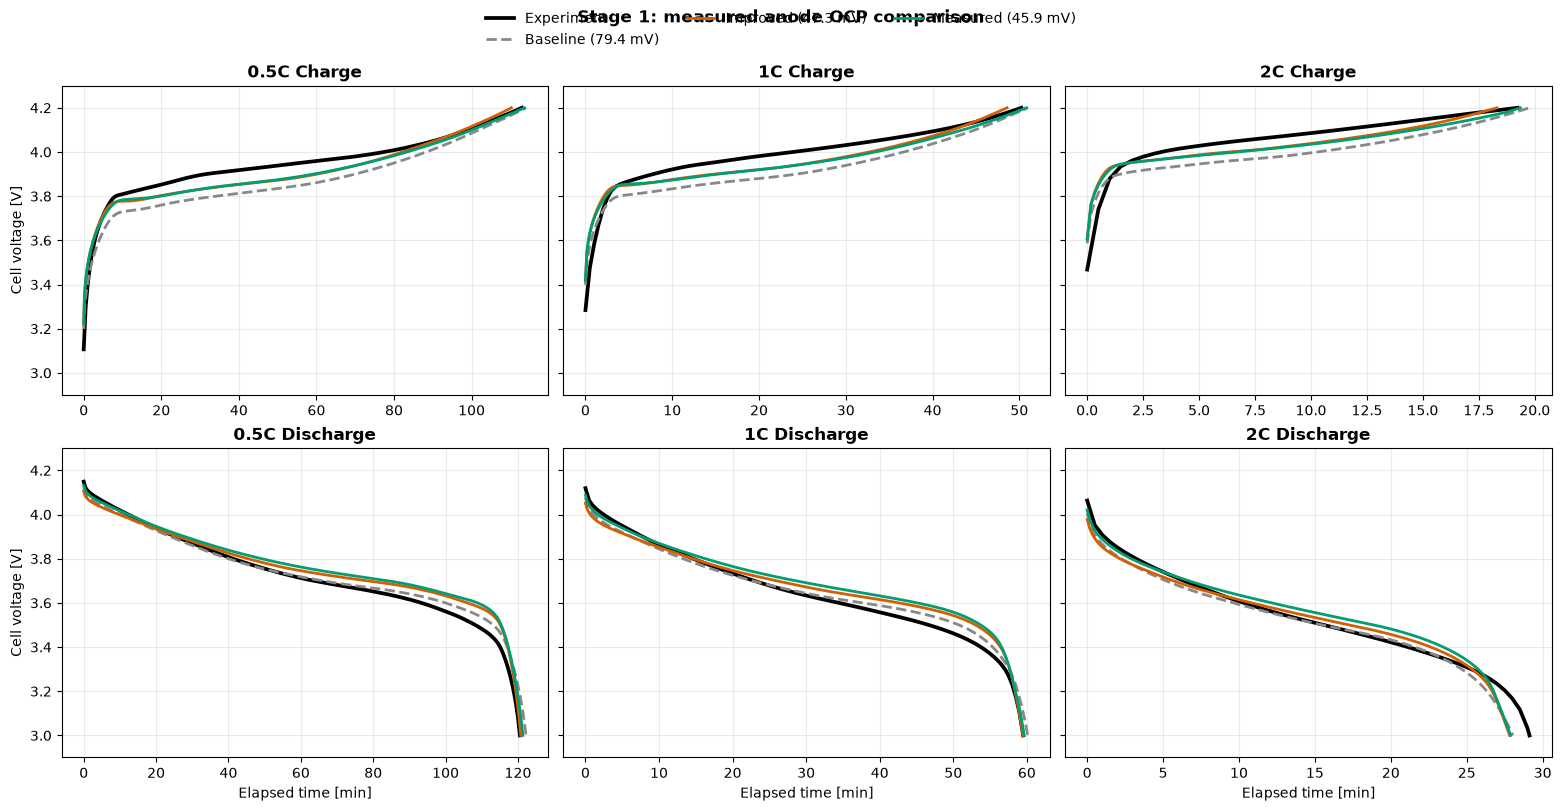

In [11]:
def rms(values):
    values = np.asarray(values, dtype=float)
    return float(np.sqrt(np.mean(values**2)))


model_summary = (
    metrics.groupby("Model", as_index=False)
    .agg(
        Voltage_full_RMSE_mV=("full_RMSE_mV", rms),
        Voltage_10_70_RMSE_mV=("center_10_70_RMSE_mV", rms),
        Cutoff_capacity_RMSE_pct=("capacity_error_pct", rms),
        Max_abs_cutoff_capacity_error_pct=("capacity_error_pct", lambda x: float(np.max(np.abs(x)))),
    )
)
display(model_summary.round(3))

colors = {
    "Baseline: Ai2020 OCP/window": "#888888",
    "Improved: measured cathode OCP/refit window": "#D55E00",
    "Measured: anode + cathode OCP/refit window": "#009E73",
}
figure, axes = plt.subplots(2, 3, figsize=(15.5, 8.0), sharey=True, constrained_layout=True)
for column, c_rate in enumerate(TEST_C_RATES):
    for row, is_charge in enumerate((True, False)):
        direction = "Charge" if is_charge else "Discharge"
        axis = axes[row, column]
        experiment = experimental_curves[(c_rate, is_charge)]
        axis.plot(experiment["time_min"], experiment["voltage_v"], color="black", lw=2.7, label="Experiment")
        for stage_name in stages:
            simulation = simulations[(stage_name, c_rate, is_charge)]
            branch = metrics[
                (metrics["Model"] == stage_name)
                & np.isclose(metrics["C-rate"], c_rate)
                & (metrics["Direction"] == direction)
            ].iloc[0]
            axis.plot(
                simulation["time_min"], simulation["voltage_v"],
                color=colors[stage_name], lw=2.0,
                ls="--" if stage_name.startswith("Baseline") else "-",
                label=f"{stage_name.split(':')[0]} ({branch.full_RMSE_mV:.1f} mV)",
            )
        axis.set_title(f"{c_rate:g}C {direction}", weight="bold")
        axis.set_ylim(2.9, 4.3)
        axis.grid(alpha=0.25)
        if row == 1:
            axis.set_xlabel("Elapsed time [min]")
        if column == 0:
            axis.set_ylabel("Cell voltage [V]")
handles, labels = axes[0, 0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside upper center", ncol=3, frameon=False)
figure.suptitle("Stage 1: measured anode OCP comparison", weight="bold")
plt.show()

## 해석 원칙

- **측정 양극만** 적용한 경우와 **측정 음극·양극 모두** 적용한 경우를 비교하면, 같은 양극 아래 음극 OCP와 재최적화 window의 영향을 볼 수 있다. 이는 음극 OCP만의 고정-window 효과와 동일하지 않다.
- qOCV 표에는 window, `Q_n/Q_p`, 측정 음극 OCP 지원 x범위를 표시한다. 고율 DFN에서 OCP 보간범위 외삽 경고가 나오면 그 branch를 별도로 해석한다.
- 표의 full_RMSE는 실험·모델 공통 시간 구간의 RMSE다. center_10_70은 실제 절대 SoC 10–70%가 아니라 branch 시작점에서 기준 용량의 10–70%에 해당하는 시간 구간이다. 조기 cutoff가 있다면 그 뒤의 누락 구간이 RMSE에 포함되지 않으므로, 해당 RMSE만으로 전체 구간 달성을 주장하지 않는다.
- `cut-off capacity error`는 4.2/3.0 V 도달 용량의 상대오차다. `D_s`, `k`, Bruggeman은 재피팅하지 않았다.
- 측정 저율 음극의 절대 x축은 Ai2020 inventory 가정에 의존한다. 음극 전위 예측은 기준전극 실측 검증이 아니다.

## 4. 음극 DRT local-minimum 적분으로 Rct·j0·k_n 초기값 계산

입력: `Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx`의 `Origin_Paste` 시트. γ는 10 mm 전극 면적을 반영한 Ω·cm² 단위이다. 각 SoC 곡선에서 N4/LF 골(0.15–0.45 Hz), N3/N4 골(3–8 Hz), N2/N3 골(50–120 Hz)을 Savitzky–Golay 평활화 후 찾는다. **저주파 바깥 골부터 고주파 바깥 골까지 원본 γ를 `d ln f`에 대해 적분**한다. 중간 골은 N3와 N4 기여도를 분리하는 데에만 사용한다. `f=1/(2πτ)`이므로 적분은 `d ln τ`와 같은 크기이다.

`R_ct,A = ∫γ d ln f`, `a_s=3ε_s/r_n`, `j₀=RT/(F R_ct,A a_s L_n)`, `k_n=j₀/[c_s,max,n √(c_e x_n(1−x_n))]`을 사용한다. `R_ct,A`는 계산 전에 Ω·cm²에서 Ω·m²로 바꾼다. 25 °C, `c_e=1000 mol m⁻³`, `ε_s,n=0.610`, `L_n=76.5 µm`, 최신 노트북 값 `r_n=3.692 µm`를 사용한다. **A2 슬라이드의 Ai2020 음극 + 측정 양극 OCP 조합**에는 `Q_cell=2.356528 Ah`, `x₀=0.003806`, `x₁₀₀=0.954221`을 대입하여 `c_s,max,n=25,182.8 mol m⁻³`를 사용한다. 현재 노트북의 같은 조합 재최적화 값은 `25,184.2 mol m⁻³`이며, 다른 **Measured anode + cathode OCP** 조합의 `32,447.1 mol m⁻³`와 구분한다. 표에 단일 값을 제시할 때는 **50% SoC**를 대표로 삼는다.

옛날 DRT 면적표에는 >10 kHz 접촉 피크가 따로 세어지지 않아, ~20 Hz와 ~1 Hz charge-transfer 피크가 **옛 N2/N3**이었다. 이후 SoC별 그림은 접촉 피크를 N1로 세어 같은 주파수대의 피크를 **현재 N3/N4**로 표기한다. 옛 N2+N3 면적은 `23.74489+6.95225=30.69714 Ω·cm²`이며, 옛 N3+N4 `12.41252 Ω·cm²`을 이력값으로 인용한 것은 번호 혼동이다. 아래의 새 Rct는 별도의 SoC별 DRT 원본을 local-minimum 방식으로 다시 적분한 값이다.

이 환산은 N3/N4를 모두 음극 charge transfer에 배정하는 가정이 있으므로, `k_n`은 DFN fitting **초기값**으로 사용한다. 원시 EIS/DRT와 전극 오염의 영향을 고려해 독립적인 확정 물성치로 취급하지 않는다.


In [12]:
# [4-1] N3+N4 local-minimum integration, A2 slide window
import openpyxl
from scipy.signal import savgol_filter

drt_candidates = [
    Path('Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx'),
    Path('outputs/Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx'),
    Path.home() / 'Downloads' / 'Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx',
]
drt_path = next((p for p in drt_candidates if p.exists()), None)
if drt_path is None:
    raise FileNotFoundError('Place Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx beside the notebook.')
drt_rows = list(openpyxl.load_workbook(drt_path, read_only=True, data_only=True)['Origin_Paste'].values)
slide_x0, slide_x100 = 0.003806, 0.954221
slide_cell_capacity_ah = 2.356528
slide_csmax_n = 3600.0 * slide_cell_capacity_ah / (
    (slide_x100 - slide_x0) * FARADAY_CONSTANT * OVERLAP_AREA_M2
    * 76.5e-6 * 0.610
)

def minimum_in_band(frequency, smoothed, lower_hz, upper_hz):
    indexes = np.flatnonzero((frequency >= lower_hz) & (frequency <= upper_hz))
    if len(indexes) < 3:
        raise ValueError(f'No local-minimum search points: {lower_hz}–{upper_hz} Hz')
    location = int(indexes[np.argmin(smoothed[indexes])])
    if location in (indexes[0], indexes[-1]):
        raise ValueError(f'Minimum on search-window edge: {frequency[location]:g} Hz')
    return location

drt_results = []
for column in range(0, 18, 2):
    soc_pct = int(str(drt_rows[0][column]).split('%')[0])
    pairs = np.array([
        (row[column], row[column + 1]) for row in drt_rows[3:]
        if isinstance(row[column], (int, float)) and isinstance(row[column + 1], (int, float))
    ], dtype=float)
    pairs = pairs[np.argsort(pairs[:, 0])]
    frequency, gamma = pairs.T
    smoothed = savgol_filter(gamma, 21, 3)
    low = minimum_in_band(frequency, smoothed, 0.15, 0.45)
    mid = minimum_in_band(frequency, smoothed, 3.0, 8.0)
    high = minimum_in_band(frequency, smoothed, 50.0, 120.0)
    r_n4 = np.trapezoid(gamma[low:mid + 1], np.log(frequency[low:mid + 1]))
    r_n3 = np.trapezoid(gamma[mid:high + 1], np.log(frequency[mid:high + 1]))
    r_ct = r_n3 + r_n4
    a_s_n = 3.0 * 0.610 / NEGATIVE_RADIUS_M
    j0_n = 8.314462618 * 298.15 / (
        FARADAY_CONSTANT * (r_ct * 1e-4) * a_s_n * 76.5e-6
    )
    x_n = slide_x0 + soc_pct / 100.0 * (slide_x100 - slide_x0)
    k_n = j0_n / (slide_csmax_n * np.sqrt(1000.0 * x_n * (1.0 - x_n)))
    measured_x_n = MEASURED_ANODE_WINDOW['x0'] + soc_pct / 100.0 * (
        MEASURED_ANODE_WINDOW['x100'] - MEASURED_ANODE_WINDOW['x0']
    )
    measured_k_n = j0_n / (
        measured_anode_csmax_n * np.sqrt(1000.0 * measured_x_n * (1.0 - measured_x_n))
    )
    drt_results.append({
        'SoC [%]': soc_pct,
        'f_low [Hz]': frequency[low], 'f_mid [Hz]': frequency[mid],
        'f_high [Hz]': frequency[high],
        'R_N4 [Ω cm²]': r_n4, 'R_N3 [Ω cm²]': r_n3,
        'Rct [Ω cm²]': r_ct, 'x_n': x_n,
        'j0 [A m⁻²]': j0_n, 'k_n A2 [A m⁻²(m³ mol⁻¹)^1.5]': k_n,
        'k_n measured anode [A m⁻²(m³ mol⁻¹)^1.5]': measured_k_n,
    })

drt_table = pd.DataFrame(drt_results).sort_values('SoC [%]', ascending=False)
display(drt_table.round({'f_low [Hz]': 4, 'f_mid [Hz]': 3, 'f_high [Hz]': 2,
                         'R_N4 [Ω cm²]': 4, 'R_N3 [Ω cm²]': 4, 'Rct [Ω cm²]': 4,
                         'x_n': 4, 'j0 [A m⁻²]': 4}))
representative = drt_table.loc[drt_table['SoC [%]'] == 50].iloc[0]
print(f"A2 c_s,max,n={slide_csmax_n:.1f} mol m⁻³")
print(f"50% SoC: Rct={representative['Rct [Ω cm²]']:.4f} Ω cm², "
      f"j0={representative['j0 [A m⁻²]']:.4f} A m⁻², "
      f"k_n(A2)={representative['k_n A2 [A m⁻²(m³ mol⁻¹)^1.5]']:.4e}")


 SoC  f_low   f_mid  f_high     R_N4     R_N3      Rct       j0           k_n
  90  0.3209   5.343   96.94   10.0544   16.8939   26.9483   0.2514  9.0771e-07
  80  0.2409   5.045   96.94    9.9093   17.1962   27.1055   0.2500  7.3940e-07
  70  0.2551   5.192   88.95    9.8930   16.3819   26.2749   0.2579  6.8820e-07
  60  0.2780   5.045   88.95    9.6376   16.5664   26.2040   0.2586  6.5665e-07
  50  0.2861   5.045   86.43    9.9608   17.0401   27.0009   0.2509  6.3079e-07
  40  0.2147   4.902   79.30   10.6163   17.1828   27.7990   0.2437  6.2932e-07
  30  0.2409   4.902   74.88   10.1227   16.6103   26.7331   0.2535  7.0218e-07
  20  0.2479   4.370   68.70    9.5603   17.3364   26.8968   0.2519  8.0016e-07
  10  0.3030   3.896   53.06    8.7910   17.7591   26.5501   0.2552  1.0738e-06
A2 c_s,max,n=25182.8 mol m⁻³
50% SoC: Rct=27.0009 Ω cm², j0=0.2509 A m⁻², k_n(A2)=6.3079e-07


## 5. 2단계: 두 OCP 조합에 실험 파라미터 순차 반영

앞의 1단계에서 생성한 `improved_parameters`(Ai2020 음극 + 측정 양극)와 `measured_anode_parameters`(측정 음극 + 측정 양극)를 사용한다. `OCP_only → +GITT Ds → +EIS kp → +DRT kn` 순서로 0.5/1/2C 충·방전을 실행한 뒤 전압 민감도와 Pearson 상관을 계산한다.

**실행 전:** 노트북의 작업 폴더에 1단계의 Excel 입력 6개와 `Ai2020_Anode_DRT_Frequency_Origin_Paste.xlsx`를 둔다. 셀 0–18 실행 후 다음 코드를 실행한다. 결과 CSV/PNG는 현재 작업 폴더에 저장된다. 2단계 코드의 음극 Rct는 앞 셀에서 검증한 N3+N4 local-minimum 50% SOC 결과를 고정해 사용한다.

In [ ]:
"""Two-OCP Stage 2: experimental Ds/kinetics and voltage identifiability.

Uses the executed Stage-1 notebook definitions, with the equivalent compact
GITT rest-end table to avoid reparsing two very large raw record sheets.
"""

from __future__ import annotations

import json
import math
from pathlib import Path
from time import monotonic

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

scope = globals()


ROOT = Path.cwd()
OUT = ROOT
OUT.mkdir(exist_ok=True)

FARADAY = 96485.33212
R_GAS = 8.314462618
T_K = 298.15
C_E = 1000.0
D_SN = 4.1707741459682473e-14
D_SP = 6.888175323807748e-14
R_CT_N = 27.000934087550903  # current 50% SoC, N3+N4 local-minimum integral
R_CT_P = 25.387  # measured cathode EIS-DRT slide
L_N, EPS_N, R_N = 76.5e-6, 0.610, 3.692e-6
L_P, EPS_P, R_P = 68.0e-6, 0.620, 4.239e-6
AI2020_K_REF = 1e-11 * FARADAY
PARAMETERS = ("Dsn", "Dsp", "kn", "kp")
RATES = (0.5, 1.0, 2.0)
CONDITIONS = tuple((rate, charge) for rate in RATES for charge in (True, False))
LOG_STEP = math.log(1.05)


def j0_from_rct(rct_ohm_cm2: float, eps_s: float, radius_m: float, thickness_m: float) -> float:
    area_resistance = rct_ohm_cm2 * 1e-4
    surface_area = 3.0 * eps_s / radius_m
    return R_GAS * T_K / (FARADAY * area_resistance * surface_area * thickness_m)


J0_N = j0_from_rct(R_CT_N, EPS_N, R_N, L_N)
J0_P = j0_from_rct(R_CT_P, EPS_P, R_P, L_P)


def cases():
    return {
        "Ai2020_anode__measured_cathode": {
            "parameters": scope["improved_parameters"],
            "window": scope["IMPROVED_WINDOW"],
            "c_s_max_n": scope["improved_csmax_n"],
            "c_s_max_p": scope["improved_csmax_p"],
            "anode_ocp": scope["AI2020_OCP"]["negative"],
            "cathode_ocp": scope["CATHODE_GITT_OCP"],
        },
        "measured_anode__measured_cathode": {
            "parameters": scope["measured_anode_parameters"],
            "window": scope["MEASURED_ANODE_WINDOW"],
            "c_s_max_n": scope["measured_anode_csmax_n"],
            "c_s_max_p": scope["measured_anode_csmax_p"],
            "anode_ocp": scope["MEASURED_ANODE_OCP"],
            "cathode_ocp": scope["CATHODE_GITT_OCP"],
        },
    }


def kinetic_constants(case):
    window = case["window"]
    x50 = (window["x0"] + window["x100"]) / 2.0
    y50 = (window["y0"] + window["y100"]) / 2.0
    kn = J0_N / (case["c_s_max_n"] * math.sqrt(C_E * x50 * (1 - x50)))
    kp = J0_P / (case["c_s_max_p"] * math.sqrt(C_E * y50 * (1 - y50)))
    return {"Dsn": D_SN, "Dsp": D_SP, "kn": kn, "kp": kp, "x50": x50, "y50": y50}


def stage_with_values(case, values, use_ds=True, use_kp=True, use_kn=True):
    changed = dict(case)
    params = case["parameters"].copy()
    updates = {}
    if use_ds:
        updates.update({
            "Negative particle diffusivity [m2.s-1]": values["Dsn"],
            "Positive particle diffusivity [m2.s-1]": values["Dsp"],
        })
    for use, label, parameter_name in (
        (use_kp, "kp", "Positive electrode exchange-current density [A.m-2]"),
        (use_kn, "kn", "Negative electrode exchange-current density [A.m-2]"),
    ):
        if use:
            original = scope["raw_parameters"][parameter_name]
            factor = values[label] / AI2020_K_REF

            def scaled(c_e, c_s_surf, c_s_max, temperature, original=original, factor=factor):
                return factor * original(c_e, c_s_surf, c_s_max, temperature)

            updates[parameter_name] = scaled
    params.update(updates)
    changed["parameters"] = params
    return changed


def run_conditions(stage, label):
    runs = {}
    for rate, charge in CONDITIONS:
        direction = "charge" if charge else "discharge"
        print("RUN", label, rate, direction, flush=True)
        runs[(rate, charge)] = scope["run_dfn_branch"](stage, rate, charge)
    return runs


def summarize_runs(case_name, phase, runs):
    rows = []
    for condition, run in runs.items():
        rate, charge = condition
        metrics = scope["compare_with_experiment"](scope["experimental_curves"][condition], run)
        rows.append({"OCP_case": case_name, "Phase": phase, "C_rate": rate,
                     "Direction": "charge" if charge else "discharge", **metrics})
    return rows


def build_sensitivity(case_name, case, values, base_runs):
    variants = {}
    for parameter in PARAMETERS:
        for sign in (-1, 1):
            changed = dict(values)
            changed[parameter] *= math.exp(sign * LOG_STEP)
            stage = stage_with_values(case, changed)
            variants[(parameter, sign)] = run_conditions(stage, f"{case_name}/{parameter}/{sign:+d}")

    # A common fixed-time window per condition is shared by all Jacobian columns.
    grids = {}
    for condition in CONDITIONS:
        exp = scope["experimental_curves"][condition]
        rate, charge = condition
        earliest_end = min(
            [base_runs[condition]["time_min"][-1]]
            + [runs[condition]["time_min"][-1] for runs in variants.values()]
        )
        t0 = 0.10 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60.0
        t1 = min(0.70 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60.0,
                 0.98 * earliest_end, 0.98 * exp["time_min"][-1])
        if t1 <= t0:
            raise RuntimeError(f"No common 10–70% capacity window: {case_name} {condition}")
        grids[condition] = np.linspace(t0, t1, 80)

    columns = []
    rows = []
    condition_rows = []
    baseline_voltage = []
    for condition in CONDITIONS:
        run = base_runs[condition]
        baseline_voltage.append(np.interp(grids[condition], run["time_min"], run["voltage_v"]))
    nominal = np.concatenate(baseline_voltage)

    for parameter in PARAMETERS:
        raw_blocks = []
        nonlin_blocks = []
        for condition in CONDITIONS:
            grid = grids[condition]
            plus = variants[(parameter, +1)][condition]
            minus = variants[(parameter, -1)][condition]
            v_plus = np.interp(grid, plus["time_min"], plus["voltage_v"])
            v_minus = np.interp(grid, minus["time_min"], minus["voltage_v"])
            base = np.interp(grid, base_runs[condition]["time_min"], base_runs[condition]["voltage_v"])
            derivative = (v_plus - v_minus) / (2.0 * LOG_STEP)
            raw_blocks.append(derivative)
            nonlin_blocks.append((v_plus + v_minus - 2 * base, v_plus - v_minus))
            rate, charge = condition
            condition_rows.append({
                "OCP_case": case_name, "C_rate": rate,
                "Direction": "charge" if charge else "discharge",
                "Parameter": parameter,
                "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
                "MaxAbs_mV_per_log_parameter": 1000 * float(np.max(np.abs(derivative))),
                "Window_start_min": float(grid[0]), "Window_end_min": float(grid[-1]),
            })
        derivative = np.concatenate(raw_blocks)
        normalized = derivative / nominal
        columns.append(normalized)
        numerator = np.linalg.norm(np.concatenate([x for x, _ in nonlin_blocks]))
        denominator = np.linalg.norm(np.concatenate([y for _, y in nonlin_blocks]))
        rows.append({
            "OCP_case": case_name, "Parameter": parameter,
            "Baseline": values[parameter],
            "RMS_normalized_sensitivity": float(np.sqrt(np.mean(normalized**2))),
            "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
            "Voltage_change_for_5pct_mV_RMS": 1000 * LOG_STEP * float(np.sqrt(np.mean(derivative**2))),
            "Central_nonlinearity_ratio": float(numerator / denominator),
        })

    matrix = np.column_stack(columns)
    corr = np.corrcoef(matrix, rowvar=False)
    rank = pd.DataFrame(rows).sort_values("RMS_normalized_sensitivity", ascending=False)
    rank["Relative_sensitivity"] = rank["RMS_normalized_sensitivity"] / rank["RMS_normalized_sensitivity"].max()
    selected = {}
    for beta in (0.8, 0.95, 0.99):
        chosen = []
        for name in rank.Parameter:
            index = PARAMETERS.index(name)
            if all(abs(corr[index, PARAMETERS.index(other)]) < beta for other in chosen):
                chosen.append(name)
        selected[str(beta)] = chosen

    unit_columns = matrix / np.linalg.norm(matrix, axis=0)
    singular = np.linalg.svd(unit_columns, compute_uv=False)
    diagnostics = {
        "OCP_case": case_name,
        "N_observations": int(len(matrix)),
        "N_parameters": len(PARAMETERS),
        "Pearson_abs_max_offdiagonal": float(np.max(np.abs(corr - np.eye(len(PARAMETERS))))),
        "Normalized_column_singular_values": [float(x) for x in singular],
        "Normalized_column_condition_number": float(singular[0] / singular[-1]),
        "Correlation_greedy_subsets": selected,
    }
    return rank, pd.DataFrame(corr, index=PARAMETERS, columns=PARAMETERS), pd.DataFrame(condition_rows), diagnostics


def main():
    start = monotonic()
    cases_dict = cases()
    parameter_rows = []
    branch_rows = []
    sensitivities = []
    correlations = {}
    condition_sensitivities = []
    diagnostics = []
    for case_name, case in cases_dict.items():
        values = kinetic_constants(case)
        parameter_rows.append({
            "OCP_case": case_name,
            "x0": case["window"]["x0"], "x100": case["window"]["x100"],
            "y0": case["window"]["y0"], "y100": case["window"]["y100"],
            "c_s_max_n_mol_m3": case["c_s_max_n"], "c_s_max_p_mol_m3": case["c_s_max_p"],
            "r_n_um": R_N * 1e6, "r_p_um": R_P * 1e6,
            "Dsn_m2_s": D_SN, "Dsp_m2_s": D_SP,
            "Rct_n_ohm_cm2": R_CT_N, "Rct_p_ohm_cm2": R_CT_P,
            "j0_n_A_m2": J0_N, "j0_p_A_m2": J0_P,
            "x_n_at_50pct": values["x50"], "y_p_at_50pct": values["y50"],
            "kn": values["kn"], "kp": values["kp"],
        })
        print("CASE", case_name, "k", values["kn"], values["kp"], flush=True)
        phases = (
            ("OCP_only", False, False, False),
            ("plus_Ds_GITT", True, False, False),
            ("plus_kp_EIS", True, True, False),
            ("plus_kn_DRT_initial", True, True, True),
        )
        final_runs = None
        for label, use_ds, use_kp, use_kn in phases:
            stage = stage_with_values(case, values, use_ds, use_kp, use_kn)
            runs = run_conditions(stage, case_name + "/" + label)
            branch_rows.extend(summarize_runs(case_name, label, runs))
            if use_kn:
                final_runs = runs
        assert final_runs is not None
        rank, corr, detail, diagnostic = build_sensitivity(case_name, case, values, final_runs)
        sensitivities.append(rank)
        correlations[case_name] = corr
        condition_sensitivities.append(detail)
        diagnostics.append(diagnostic)

    parameters = pd.DataFrame(parameter_rows)
    branches = pd.DataFrame(branch_rows)
    aggregate = branches.groupby(["OCP_case", "Phase"], sort=False).agg(
        Full_RMSE_mV=("full_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Center_10_70_RMSE_mV=("center_10_70_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Mean_abs_capacity_error_pct=("capacity_error_pct", lambda x: float(np.mean(np.abs(x)))),
    ).reset_index()
    ranking = pd.concat(sensitivities, ignore_index=True)
    detail = pd.concat(condition_sensitivities, ignore_index=True)

    for name, frame in (
        ("Stage2_two_OCP_parameters.csv", parameters),
        ("Stage2_two_OCP_branch_metrics.csv", branches),
        ("Stage2_two_OCP_phase_summary.csv", aggregate),
        ("Stage2_two_OCP_sensitivity.csv", ranking),
        ("Stage2_two_OCP_condition_sensitivity.csv", detail),
    ):
        frame.to_csv(OUT / name, index=False, encoding="utf-8-sig")
    for case_name, matrix in correlations.items():
        matrix.to_csv(OUT / f"Stage2_{case_name}_Pearson_correlation.csv", encoding="utf-8-sig")
    (OUT / "Stage2_two_OCP_identifiability.json").write_text(
        json.dumps(diagnostics, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
    for ax, (case_name, group) in zip(axes, aggregate.groupby("OCP_case", sort=False)):
        x = np.arange(len(group))
        ax.plot(x, group["Center_10_70_RMSE_mV"], "o-", color="#2458b4", lw=2)
        ax.set_xticks(x, ["OCP", "+Ds", "+kp", "+kn"])
        ax.set_title(case_name.replace("__", " + ").replace("_", " "), fontsize=10)
        ax.set_ylabel("10–70% window RMSE (mV)")
        ax.grid(alpha=0.25)
    fig.savefig(OUT / "Stage2_two_OCP_phase_RMSE.png", dpi=180)
    plt.close(fig)

    print("\nPARAMETERS\n", parameters.to_string(index=False), flush=True)
    print("\nAGGREGATE\n", aggregate.to_string(index=False), flush=True)
    print("\nSENSITIVITY\n", ranking.to_string(index=False), flush=True)
    print("\nIDENTIFIABILITY\n", json.dumps(diagnostics, ensure_ascii=False, indent=2), flush=True)
    print("ELAPSED", round(monotonic() - start, 1), "seconds", flush=True)


main()


## 6. 2단계 해석 요약

실험값을 순차 대입한 최종 전압 RMSE는 두 OCP 모두 전체 약 **37 mV**, 중앙 10–70% 약 **17 mV**였다. `Ds`만 대입하면 오차가 증가했고, `kp`와 `kn`을 차례로 대입하면 감소했다. 이는 실험값 대입 검증이지 최적화 피팅은 아니다.

COBRAPRO 방식으로 계산한 전압 국소 민감도에서는 `kn`과 `kp`가 매우 강하게 상관되어 동시 식별이 어렵다. `Ds`의 5% 변화가 만드는 전압 신호는 0.07–0.12 mV RMS로 작다. 자세한 숫자와 해석 범위는 `Stage2_two_OCP_결과요약.md`를 참고한다.

### 추가 확인: nominal Ds와 GITT Ds의 비교는 k에 따라 달라진다

앞 표의 `OCP_only → +Ds` 비교는 기존 Ai2020 k를 사용한다. 아래 셀은 `kp`, `kn`을 실험값으로 **동일하게 고정**한 후 `Dsn`, `Dsp`를 각각 nominal/GITT로 교체한다. 두 OCP 모두 이 상태에서는 GITT 양극 `Dsp`를 사용했을 때 전압 RMSE가 낮았다. 따라서 nominal Ds가 일반적으로 더 낫다고 판단하지 않는다.

In [ ]:
"""Check Ds alternatives at fixed measured kinetic constants, one factor at a time."""

import json
from pathlib import Path

import numpy as np
import pandas as pd

scope = globals()


OUT = Path.cwd()
raw = scope["raw_parameters"]
def scalar(value):
    return float(value.evaluate()) if hasattr(value, "evaluate") else float(value)


nominal_n = scalar(raw["Negative particle diffusivity [m2.s-1]"](0.5, 298.15))
nominal_p = scalar(raw["Positive particle diffusivity [m2.s-1]"](0.7, 298.15))
conditions = tuple((rate, charge) for rate in (0.5, 1.0, 2.0) for charge in (True, False))
rows = []
for case_name, case in cases().items():
    values = kinetic_constants(case)
    variants = {
        "nominal_both": (nominal_n, nominal_p),
        "GITT_n_only": (values["Dsn"], nominal_p),
        "GITT_p_only": (nominal_n, values["Dsp"]),
        "GITT_both": (values["Dsn"], values["Dsp"]),
    }
    for label, (dsn, dsp) in variants.items():
        adjusted = {**values, "Dsn": dsn, "Dsp": dsp}
        stage = stage_with_values(case, adjusted)
        metrics = []
        for rate, charge in conditions:
            run = scope["run_dfn_branch"](stage, rate, charge)
            metrics.append(scope["compare_with_experiment"](scope["experimental_curves"][(rate, charge)], run))
        rows.append({
            "OCP_case": case_name,
            "Ds_variant": label,
            "Dsn_m2_s": dsn,
            "Dsp_m2_s": dsp,
            "Full_RMSE_mV": float(np.sqrt(np.mean([m["full_RMSE_mV"] ** 2 for m in metrics]))),
            "Center_10_70_RMSE_mV": float(np.sqrt(np.mean([m["center_10_70_RMSE_mV"] ** 2 for m in metrics]))),
        })
result = pd.DataFrame(rows)
result.to_csv(OUT / "Stage2_Ds_nominal_vs_GITT_fixed_k.csv", index=False, encoding="utf-8-sig")
print(result.to_string(index=False))


## 7. 전체 실험값 개선 및 Bruggeman 포함 민감도

공통 구조 보정 Ai2020 기준과 최종 실험값 모델을 같은 여섯 CC 조건으로 재계산한다. 이어서 `Dsn`, `Dsp`, `kn`, `kp`, `brugg_n`, `brugg_s`, `brugg_p`의 정규화 전압 민감도와 Pearson 상관을 계산한다. Bruggeman 계수는 전해질 유효수송값을 뜻하며 기준값 2.914/1.500/1.830에서 교란한다. 보고서는 `Stage2_전체실험값_7파라미터_결과요약.md`를 참고한다.

In [ ]:
"""Current two-OCP, seven-parameter voltage LSA including electrolyte Bruggeman exponents."""

from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

scope = globals()


OUT = Path.cwd()
OUT.mkdir(exist_ok=True)
PARAMETERS = ("Dsn", "Dsp", "kn", "kp", "brugg_n", "brugg_s", "brugg_p")
BRUGG_KEYS = {
    "brugg_n": "Negative electrode Bruggeman coefficient (electrolyte)",
    "brugg_s": "Separator Bruggeman coefficient (electrolyte)",
    "brugg_p": "Positive electrode Bruggeman coefficient (electrolyte)",
}
CONDITIONS = tuple((rate, charge) for rate in (0.5, 1.0, 2.0) for charge in (True, False))
STEP = math.log(1.05)


def stage_with_seven(case, values):
    stage = stage_with_values(case, values)
    parameters = stage["parameters"].copy()
    parameters.update({key: values[name] for name, key in BRUGG_KEYS.items()})
    stage["parameters"] = parameters
    return stage


def run_six(stage):
    return {condition: scope["run_dfn_branch"](stage, *condition) for condition in CONDITIONS}


def metrics(case_name, phase, runs):
    rows = []
    for (rate, charge), run in runs.items():
        metric = scope["compare_with_experiment"](scope["experimental_curves"][(rate, charge)], run)
        rows.append({"OCP_case": case_name, "Phase": phase, "C_rate": rate,
                     "Direction": "charge" if charge else "discharge", **metric})
    return rows


def grids_for(runs):
    grids = {}
    for condition in CONDITIONS:
        exp = scope["experimental_curves"][condition]
        first_end = min(run[condition]["time_min"][-1] for run in runs)
        t0 = 0.10 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60
        t1 = min(0.70 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60,
                 0.98 * first_end, 0.98 * exp["time_min"][-1])
        if t1 <= t0:
            raise RuntimeError(f"No common sensitivity interval for {condition}")
        grids[condition] = np.linspace(t0, t1, 80)
    return grids


def sensitivity(case_name, case, values, base_runs):
    variants = {}
    for parameter in PARAMETERS:
        for sign in (-1, +1):
            perturbed = dict(values)
            perturbed[parameter] *= math.exp(sign * STEP)
            print("SENS", case_name, parameter, sign, flush=True)
            variants[(parameter, sign)] = run_six(stage_with_seven(case, perturbed))
    grids = grids_for([base_runs, *variants.values()])
    nominal = np.concatenate([
        np.interp(grids[condition], base_runs[condition]["time_min"], base_runs[condition]["voltage_v"])
        for condition in CONDITIONS
    ])
    columns = []
    rows = []
    condition_rows = []
    for parameter in PARAMETERS:
        derivative_blocks = []
        nonlinear_blocks = []
        difference_blocks = []
        for condition in CONDITIONS:
            grid = grids[condition]
            plus = variants[(parameter, +1)][condition]
            minus = variants[(parameter, -1)][condition]
            base = base_runs[condition]
            vp = np.interp(grid, plus["time_min"], plus["voltage_v"])
            vm = np.interp(grid, minus["time_min"], minus["voltage_v"])
            v0 = np.interp(grid, base["time_min"], base["voltage_v"])
            derivative = (vp - vm) / (2 * STEP)
            derivative_blocks.append(derivative)
            nonlinear_blocks.append(vp + vm - 2 * v0)
            difference_blocks.append(vp - vm)
            condition_rows.append({
                "OCP_case": case_name, "Parameter": parameter,
                "C_rate": condition[0], "Direction": "charge" if condition[1] else "discharge",
                "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
                "Window_start_min": float(grid[0]), "Window_end_min": float(grid[-1]),
            })
        derivative = np.concatenate(derivative_blocks)
        normalized = derivative / nominal
        columns.append(normalized)
        rows.append({
            "OCP_case": case_name, "Parameter": parameter, "Baseline": values[parameter],
            "RMS_normalized_sensitivity": float(np.sqrt(np.mean(normalized**2))),
            "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
            "Voltage_change_for_5pct_mV_RMS": 1000 * STEP * float(np.sqrt(np.mean(derivative**2))),
            "Central_nonlinearity_ratio": float(
                np.linalg.norm(np.concatenate(nonlinear_blocks))
                / np.linalg.norm(np.concatenate(difference_blocks))
            ),
        })
    matrix = np.column_stack(columns)
    corr = pd.DataFrame(np.corrcoef(matrix, rowvar=False), index=PARAMETERS, columns=PARAMETERS)
    rank = pd.DataFrame(rows).sort_values("RMS_normalized_sensitivity", ascending=False)
    rank["Relative_sensitivity"] = rank.RMS_normalized_sensitivity / rank.RMS_normalized_sensitivity.max()
    subset = {}
    for threshold in (.8, .95, .99):
        chosen = []
        for candidate in rank.Parameter:
            if all(abs(corr.loc[candidate, selected]) < threshold for selected in chosen):
                chosen.append(candidate)
        subset[str(threshold)] = chosen
    singular = np.linalg.svd(matrix / np.linalg.norm(matrix, axis=0), compute_uv=False)
    diagnostic = {
        "OCP_case": case_name,
        "Observation_count": int(len(matrix)),
        "Candidate_parameters": list(PARAMETERS),
        "Singular_values_unit_columns": [float(x) for x in singular],
        "Condition_number_unit_columns": float(singular[0] / singular[-1]),
        "Correlation_greedy_subsets": subset,
    }
    return rank, corr, condition_rows, diagnostic


def main():
    all_metrics = []
    all_sensitivities = []
    all_condition_sensitivities = []
    all_diagnostics = []
    baseline = {
        "parameters": scope["common_parameters"],
        "window": scope["PUBLISHED_WINDOW"],
        "c_s_max_n": scope["baseline_csmax_n"],
        "c_s_max_p": scope["baseline_csmax_p"],
        "anode_ocp": scope["AI2020_OCP"]["negative"],
        "cathode_ocp": scope["AI2020_OCP"]["positive"],
    }
    print("RUN common geometry + Ai2020 OCP/nominal transport/kinetics baseline", flush=True)
    all_metrics.extend(metrics("Ai2020_common_baseline", "baseline", run_six(baseline)))
    for case_name, case in cases().items():
        values = kinetic_constants(case)
        values.update({name: float(case["parameters"][key]) for name, key in BRUGG_KEYS.items()})
        print("RUN final", case_name, values, flush=True)
        runs = run_six(stage_with_seven(case, values))
        all_metrics.extend(metrics(case_name, "experimental_all", runs))
        rank, corr, detail, diagnostic = sensitivity(case_name, case, values, runs)
        all_sensitivities.append(rank)
        all_condition_sensitivities.extend(detail)
        all_diagnostics.append(diagnostic)
        corr.to_csv(OUT / f"Stage2_{case_name}_seven_parameter_Pearson.csv", encoding="utf-8-sig")
    branches = pd.DataFrame(all_metrics)
    summary = branches.groupby(["OCP_case", "Phase"], sort=False).agg(
        Full_RMSE_mV=("full_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Center_10_70_RMSE_mV=("center_10_70_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Capacity_error_RMSE_pct=("capacity_error_pct", lambda x: float(np.sqrt(np.mean(np.square(x))))),
    ).reset_index()
    branches.to_csv(OUT / "Stage2_full_experimental_branch_comparison.csv", index=False, encoding="utf-8-sig")
    summary.to_csv(OUT / "Stage2_full_experimental_summary.csv", index=False, encoding="utf-8-sig")
    pd.concat(all_sensitivities, ignore_index=True).to_csv(
        OUT / "Stage2_seven_parameter_sensitivity.csv", index=False, encoding="utf-8-sig"
    )
    pd.DataFrame(all_condition_sensitivities).to_csv(
        OUT / "Stage2_seven_parameter_condition_sensitivity.csv", index=False, encoding="utf-8-sig"
    )
    (OUT / "Stage2_seven_parameter_identifiability.json").write_text(
        json.dumps(all_diagnostics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("\nSUMMARY\n", summary.to_string(index=False), flush=True)
    print("\nSENSITIVITY\n", pd.concat(all_sensitivities).to_string(index=False), flush=True)
    print("\nIDENTIFIABILITY\n", json.dumps(all_diagnostics, indent=2), flush=True)


main()
